In [7]:
import os
import glob
import re
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11})

target_dir = os.path.expanduser("~/Downloads")
search_pattern = os.path.join(target_dir, "Flow_*_hist.npy")
files = sorted(glob.glob(search_pattern))

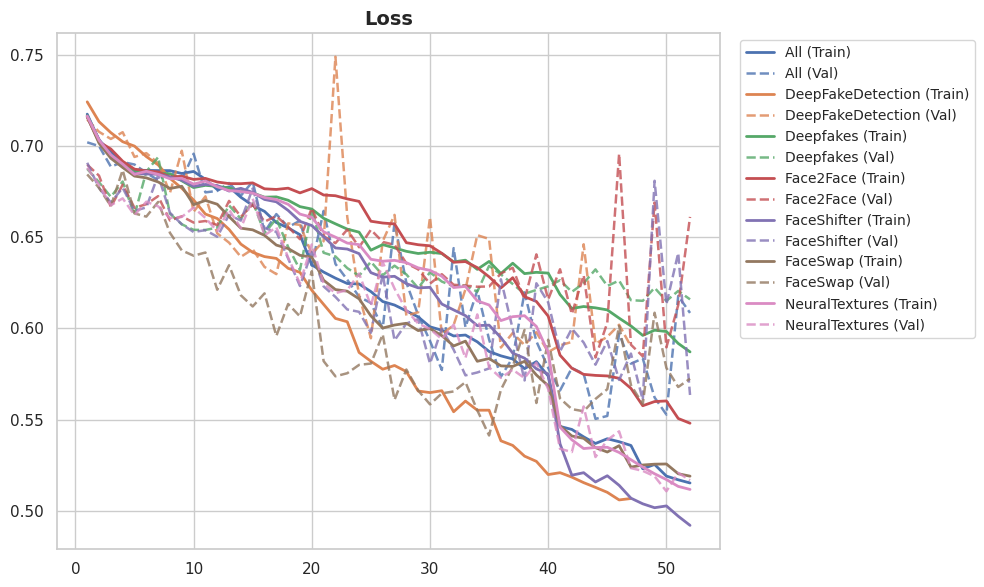

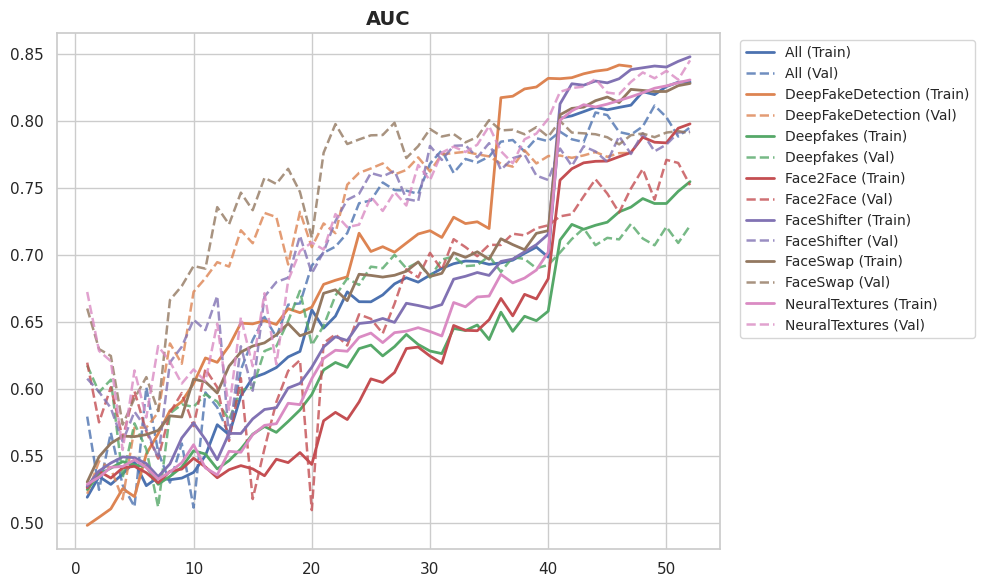

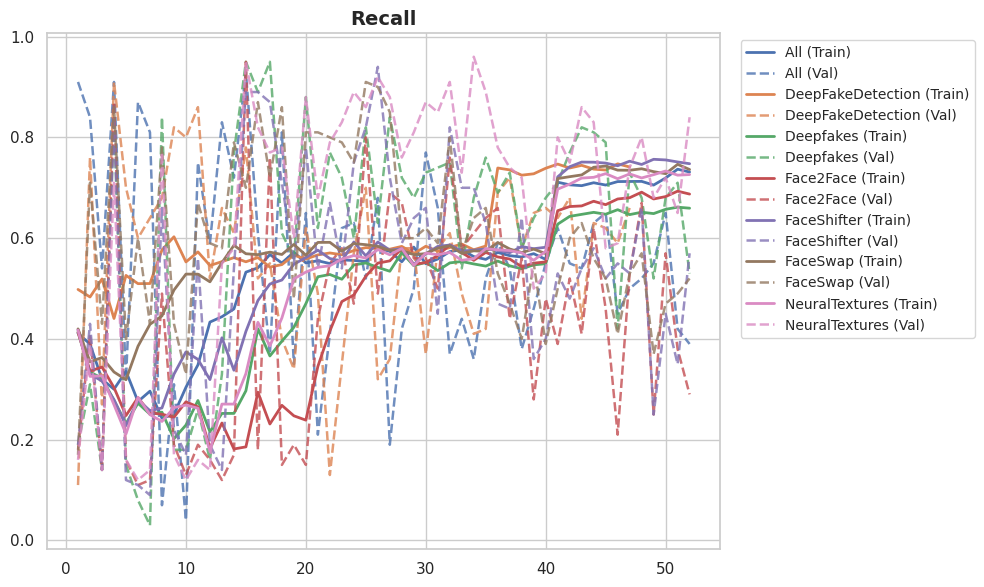

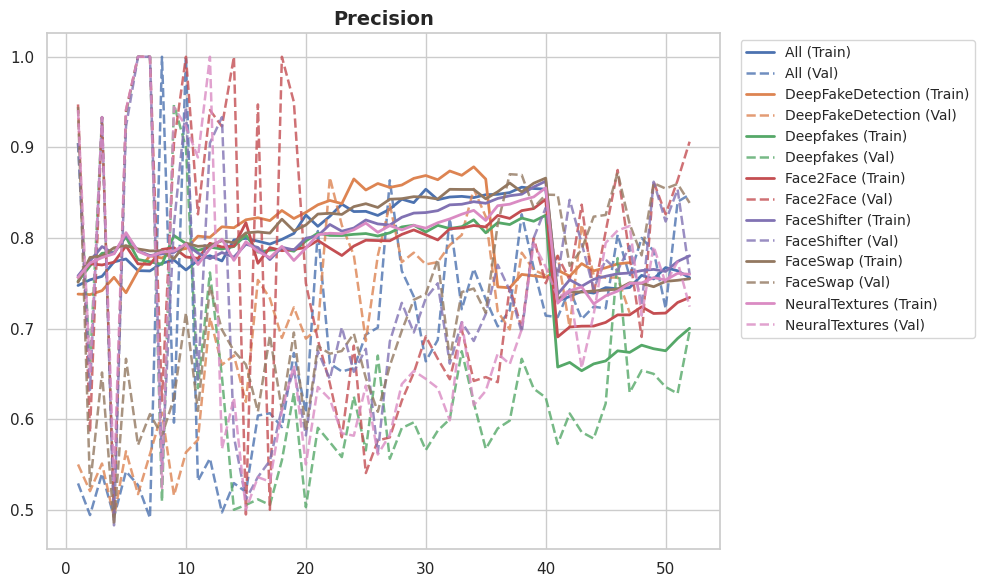

In [10]:
histories = {}

for filepath in files:
    method_name = re.sub(r".*Flow_(.*?)_hist\.npy$", r"\1", filepath)
    
    data = np.load(filepath, allow_pickle=True)
    if isinstance(data, np.ndarray) and data.shape == ():
        data = data.item()
    histories[method_name] = data

metrics_info = [
    ('loss', 'Loss'),
    ('auc', 'AUC'),
    ('recall', 'Recall'),
    ('precision', 'Precision')
]

for metric_key, title in metrics_info:
    plt.figure(figsize=(10, 6))
    ax = plt.gca()
    
    for method, hist in histories.items():
        if isinstance(hist, dict):
            train_vals = hist.get(metric_key, [])
            val_vals = hist.get(f'val_{metric_key}', [])
        elif hasattr(hist, 'history'):
            train_vals = hist.history.get(metric_key, [])
            val_vals = hist.history.get(f'val_{metric_key}', [])
        else:
            continue
        
        if len(train_vals) == 0:
            continue

        epochs = range(1, len(train_vals) + 1)
        line, = ax.plot(epochs, train_vals, label=f"{method} (Train)", linewidth=2)
        
        if len(val_vals) > 0:
            ax.plot(epochs, val_vals, label=f"{method} (Val)", linestyle='--', color=line.get_color(), alpha=0.8, linewidth=1.8)

    plt.title(title, fontsize=14, fontweight='bold')
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10, frameon=True)
    plt.tight_layout()
    plt.show()